In [1]:
%pip install -q pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


# 01. Market history: bull and bear periods

A bull market is a long rise. A bear market is a long fall, usually
defined as a fall of 20 percent or more from a peak. Neither word is a
promise. They are labels we put on the past after we see the shape.

In this notebook we plot the S and P 500 on a log scale. A log scale is
a chart where equal distances mean equal percent changes, not equal
dollar changes. That matters because the index went from about 93 in
1970 to over 7,500 in 2026. On a normal scale, the early years would look
flat even when they moved a lot in percent terms. On a log scale, a 10
percent move looks the same size in 1975 and in 2025.

We also rebase two indexes to 100 at the start. Rebasing means dividing
every value by the first value and multiplying by 100. Both series then
start at 100, so we can compare their growth even though their starting
levels are very different.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
ROOT = Path("..").resolve()
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"
print("Charts will be saved to:", CHARTS)

Charts will be saved to: /home/hatch/workspace/repo-builds/finance-analytics/charts


In [3]:
sp = pd.read_csv(PROC / "sp500_daily.csv", parse_dates=["date"])
both = pd.read_csv(PROC / "sp500_nasdaq_daily.csv", parse_dates=["date"])
annual = pd.read_csv(PROC / "sp500_annual.csv")
era = pd.read_csv(PROC / "sp500_by_era.csv")
print(era.to_string(index=False))
print()
print("Best calendar year in the file:")
print(annual.loc[annual["annual_return_pct"].idxmax()].to_string())
print()
print("Worst calendar year in the file:")
print(annual.loc[annual["annual_return_pct"].idxmin()].to_string())

                       era  start_close  end_close  cagr_pct  annual_vol_pct  return_per_unit_risk  max_drawdown_pct  n_trading_days
1970s (partial, from 1970)        93.00     107.94      1.50           13.60                  0.11            -48.20            2526
                     1980s       105.76     353.40     12.84           17.13                  0.75            -33.51            2528
                     1990s       359.69    1469.25     15.12           14.10                  1.07            -19.92            2528
                     2000s      1455.22    1115.10     -2.63           22.23                 -0.12            -56.78            2515
                     2010s      1132.99    3230.78     11.06           14.77                  0.75            -34.67            2516
  2020s (partial, to 2026)      3257.85    7541.40     13.07           20.12                  0.65            -33.92            1718

Best calendar year in the file:
year                 1995.000000
yea

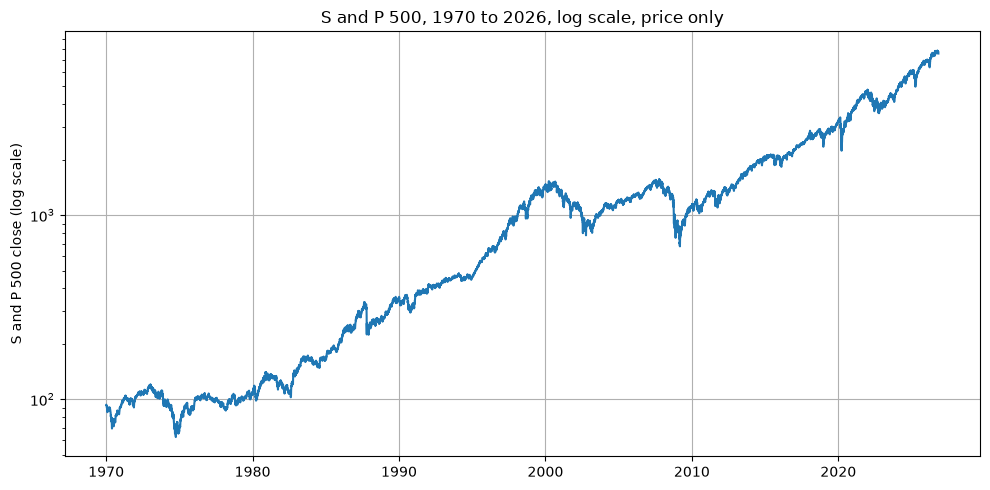

In [4]:
fig, ax = plt.subplots()
ax.plot(sp["date"], sp["sp500"])
ax.set_yscale("log")
ax.set_ylabel("S and P 500 close (log scale)")
ax.set_title("S and P 500, 1970 to 2026, log scale, price only")
plt.tight_layout()
plt.savefig(CHARTS / "01_sp500_log.png", dpi=150)
plt.show()

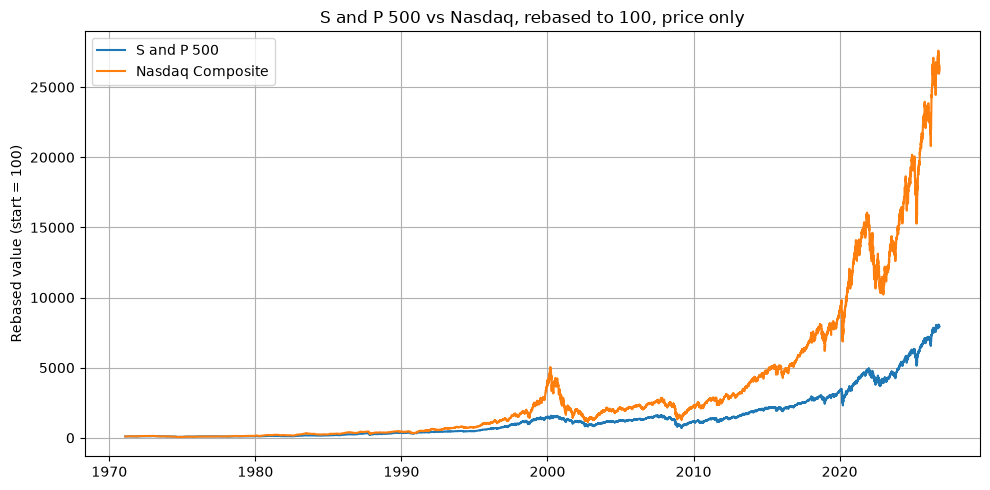

Nasdaq rebased end: 26184.7
S and P 500 rebased end: 7964.9


In [5]:
fig, ax = plt.subplots()
ax.plot(both["date"], both["sp500_rebased"], label="S and P 500")
ax.plot(both["date"], both["nasdaq_rebased"], label="Nasdaq Composite")
ax.set_ylabel("Rebased value (start = 100)")
ax.set_title("S and P 500 vs Nasdaq, rebased to 100, price only")
ax.legend()
plt.tight_layout()
plt.savefig(CHARTS / "01_sp500_vs_nasdaq.png", dpi=150)
plt.show()
print("Nasdaq rebased end:", round(both["nasdaq_rebased"].iloc[-1], 1))
print("S and P 500 rebased end:", round(both["sp500_rebased"].iloc[-1], 1))

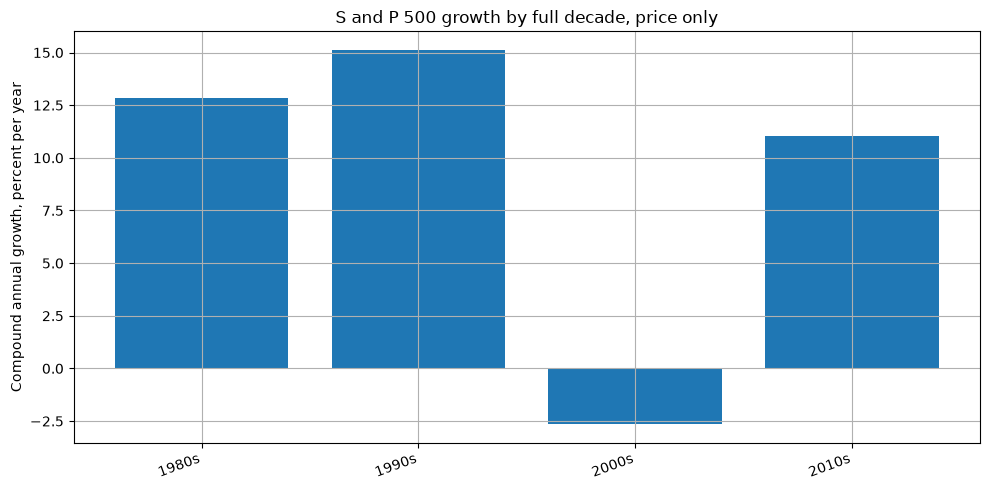

In [6]:
plot_era = era[~era["era"].str.contains("partial")]
fig, ax = plt.subplots()
ax.bar(plot_era["era"], plot_era["cagr_pct"])
ax.set_ylabel("Compound annual growth, percent per year")
ax.set_title("S and P 500 growth by full decade, price only")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(CHARTS / "01_decade_cagr.png", dpi=150)
plt.show()

## What we learned, in plain words

The long rise is real, but it was not smooth. The 2000s ended lower than
they started on a price basis, with a compound annual growth rate of
about minus 2.6 percent per year. The 1990s were the strongest full
decade in this file, at about 15.1 percent per year. The worst single
calendar year was 2008, at about minus 38.5 percent. The best was 1995,
at about plus 34.1 percent.

A beginner takeaway: a long chart that goes up does not mean every year
goes up. It means the up years, over a very long time, outweighed the
down years. That is why the next notebook looks at how rough the ride
was along the way.